# First look at a historical hindcast

Start with the solved **2023** network copied from Sophia. Run the cells from top to bottom. Nothing here solves, rebuilds or overwrites the network.

You will inspect:
- the network and solve metadata;
- bidding-zone prices, their spread over time and duration curves;
- electricity supply, demand and storage;
- flows into and out of one selected zone;
- any load shedding;
- an optional first comparison with historical prices.

Use your local PyPSA-Eur Python interpreter. Change the settings in the next cell to explore a different year or region. The other HPC jobs can keep running independently.

**Required local files**
- `results/hindcast-build-2023/network.nc`
- `data/hindcast/bus_zones_2023.csv`

The repository also supplies the benchmark configuration and helper functions. The optional historical-price CSV is only needed in the final comparison section. All times below are **UTC**. Successful optimisation alone does not establish historical accuracy.

**Extended diagnostics (sections 9–15)** inspect the currently loaded result.
They do not apply the geographic correction or change dispatch. In particular,
the original 2023 solution can still contain Ringhals/Oskarshamn in SE4.
Pulling newer source code does not retroactively correct an exported network.

## 1. Choose the year and zones

The defaults focus on Denmark and nearby markets. Prices will still be extracted for the entire model. Set `PROJECT_ROOT` only if this notebook is opened outside the PyPSA-Eur checkout.

In [173]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pypsa
from IPython.display import display

YEAR = 2023
FOCUS_ZONE = "SE_2"
PRICE_ZONES = ["DK_1", "DK_2", "DE_LU", "SE_4", "SE_2", "NO_2"]
START = f"{YEAR}-01-01"
END = f"{YEAR}-01-07"  # A date without a time includes that whole day.

# Extended diagnostics: focus on Nordic zones and nearby markets.
DIAG_ZONES = ["DK_1", "DK_2", "SE_1", "SE_2", "SE_3", "SE_4",
              "NO_1", "NO_2", "NO_3", "NO_4", "NO_5", "FI", "DE_LU"]
PRICE_MATCH_ATOL = 0.10  # EUR/MWh: descriptive price/cost proximity.
POWER_BOUND_RTOL = 1e-5  # Relative to component nominal MW; at least 0.01 MW.
SOC_BOUND_RTOL = 0.01   # Within 1% of energy capacity counts as near a reservoir bound.
PRICE_BIN_WIDTH = 1.0   # EUR/MWh, used only to describe price concentration.

# Example if opened in another project:
# PROJECT_ROOT = Path("~/PycharmProjects/pypsa-eur").expanduser()
PROJECT_ROOT = None

if PROJECT_ROOT is None:
    candidates = [Path.cwd(), *Path.cwd().parents]
    PROJECT_ROOT = next(
        (p for p in candidates if (p / "scripts/hindcast.py").is_file()), None
    )
if PROJECT_ROOT is None:
    raise FileNotFoundError("Set PROJECT_ROOT to your local pypsa-eur checkout.")
PROJECT_ROOT = Path(PROJECT_ROOT).expanduser().resolve()
os.chdir(PROJECT_ROOT)  # The shared benchmark configuration uses repository-relative paths.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.hindcast import (
    benchmark_config, zonal_configuration, region_buses, model_prices,
    border_flows, load_shedding, read_hourly, reference_prices, paired_metrics,
)

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.2})
pd.set_option("display.max_rows", 60)
print("Project:", PROJECT_ROOT)
print("PyPSA:", pypsa.__version__)

Project: /home/tom/PycharmProjects/pypsa-eur
PyPSA: 1.3.0


## 2. Load the solved network

Loading can take a little while on the laptop. A populated marginal-price table is needed; an unsolved `composed_YEAR.nc` is not a substitute for the exported solution.

In [174]:
cfg = benchmark_config("config/hindcast/benchmark.yaml", year=YEAR)
NETWORK = PROJECT_ROOT / cfg["network"]
MAPPING = PROJECT_ROOT / cfg["bus_zones"]

for path in [NETWORK, MAPPING]:
    if not path.is_file():
        raise FileNotFoundError(f"Copy this file from Sophia first: {path}")

n = pypsa.Network(NETWORK)
if n.buses_t.marginal_price.empty:
    raise ValueError("No solved bus prices found. Load the exported solved network.")
if set(pd.DatetimeIndex(n.snapshots).year) != {YEAR}:
    raise ValueError("The network snapshots do not match YEAR.")

overview = pd.Series({
    "Year": YEAR,
    "Snapshots": len(n.snapshots),
    "Buses": len(n.buses),
    "Generators": len(n.generators),
    "Storage units": len(n.storage_units),
    "AC lines": len(n.lines),
    "Links (including DC and internal market links)": len(n.links),
    "Network size (MB)": round(NETWORK.stat().st_size / 1e6, 1),
})
display(overview.to_frame("Value"))

provenance = n.meta.get("hindcast_reproduction", {})
display(pd.Series({
    "Solver": provenance.get("solver", "not recorded"),
    "Status": provenance.get("solver_status", "not recorded"),
    "Termination": provenance.get("termination_condition", "not recorded"),
    "Solver options": provenance.get("solver_options", "not recorded"),
    "Source network SHA256": provenance.get("source_sha256", "not recorded"),
}).to_frame("Recorded solve metadata"))

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.3.0)
INFO:pypsa.network.io:Imported network 'Unnamed Network' has buses, carriers, generators, global_constraints, lines, links, loads, storage_units, sub_networks


,Value
Year,2023.0
Snapshots,8760.0
Buses,52.0
Generators,763.0
Storage units,71.0
AC lines,73.0
Links (including DC and internal market links),37.0
Network size (MB),79.8


,Recorded solve metadata
Solver,gurobi
Status,ok
Termination,optimal
Solver options,"{'Threads': 8, 'Method': 2, 'Crossover': -1, '..."
Source network SHA256,c572b901ed64af73cce9221ce8b38296d43531dc8b3b0f...


## 3. Read one common price per bidding zone

This reuses the benchmark's explicit mapping and its shared-market checks. DE–LU and the Irish market keep their national asset information while sharing a common price. Prices are not averaged across disagreeing buses.

The separate model regions `ESMA` (Mallorca), `FR15` (Corsica) and `GBZE` (Shetland) are retained. They have no assigned historical-price reference and are labelled **model-only** below.

In [175]:
cfg = zonal_configuration(n, cfg)
mapping = region_buses(n, cfg["regions"])
price_checks = {}
prices = model_prices(
    n, mapping, mode="common",
    atol=cfg.get("price_atol", 0.01),
    rtol=cfg.get("price_rtol", 1e-6),
    checks=price_checks,
)

if FOCUS_ZONE not in prices:
    raise ValueError(f"Unknown FOCUS_ZONE. Available labels: {list(prices.columns)}")
selected = [zone for zone in PRICE_ZONES if zone in prices]
if not selected:
    raise ValueError("None of PRICE_ZONES is present in the network.")
missing_selected = sorted(set(PRICE_ZONES) - set(selected))
if missing_selected:
    print("Not present in this model:", missing_selected)

price_summary = prices.describe(percentiles=[0.05, 0.5, 0.95]).T
price_summary = price_summary.rename(columns={
    "count": "Hours", "mean": "Mean", "std": "Std", "min": "Min",
    "5%": "P05", "50%": "Median", "95%": "P95", "max": "Max",
})
price_summary["Negative hours"] = prices.lt(0).sum()
price_summary["Reference"] = [
    "model-only" if cfg["regions"][zone].get("unscored_reason") else "price area"
    for zone in price_summary.index
]
display(price_summary.sort_values("Mean").round(2))
print("All price statistics are EUR/MWh; these means are unweighted hourly means.")

,Hours,Mean,Std,Min,P05,Median,P95,Max,Negative hours,Reference
SE_1,8760.0,80.05,12.29,19.90,61.75,83.26,83.26,107.66,0,price area
SE_3,8760.0,80.07,12.25,19.98,62.45,83.26,83.26,108.72,0,price area
SE_2,8760.0,80.07,12.24,18.64,60.94,83.26,83.26,107.96,0,price area
FI,8760.0,80.08,12.13,19.98,62.45,83.26,83.26,107.61,0,price area
SE_4,8760.0,80.38,12.84,19.98,62.45,83.26,83.26,152.39,0,price area
DK_2,8760.0,80.40,12.92,19.98,62.45,83.26,83.26,152.39,0,price area
NO_4,8760.0,81.99,6.94,19.98,80.02,83.26,83.26,106.55,0,price area
NO_3,8760.0,82.41,5.54,19.98,81.82,83.26,83.26,103.81,0,price area
NO_5,8760.0,82.43,5.50,19.98,82.21,83.26,83.26,102.39,0,price area
NO_2,8760.0,82.44,5.50,19.98,82.39,83.26,83.26,102.29,0,price area


All price statistics are EUR/MWh; these means are unweighted hourly means.


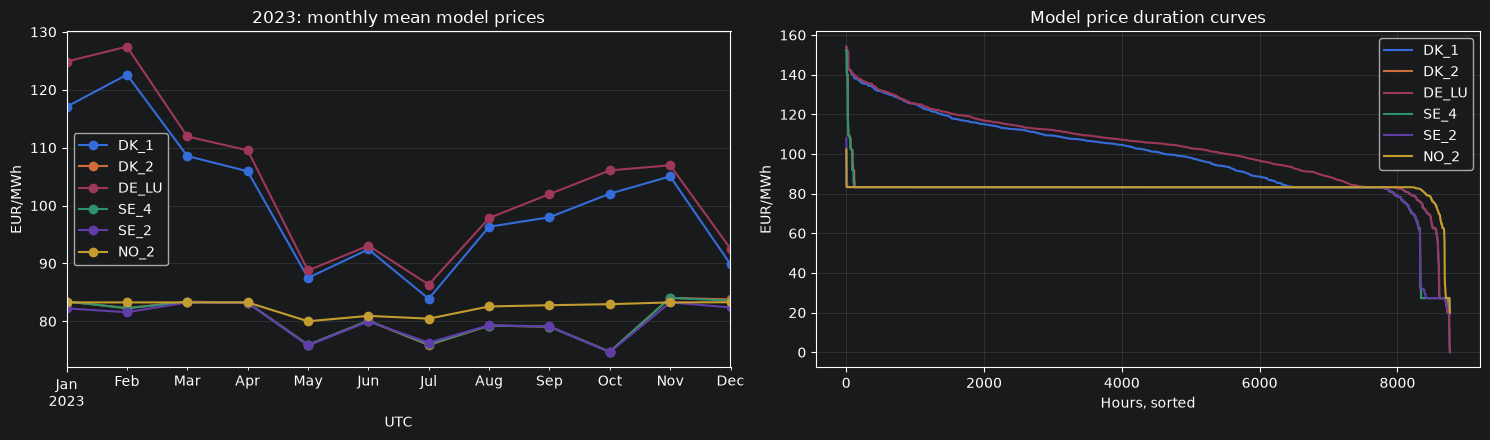

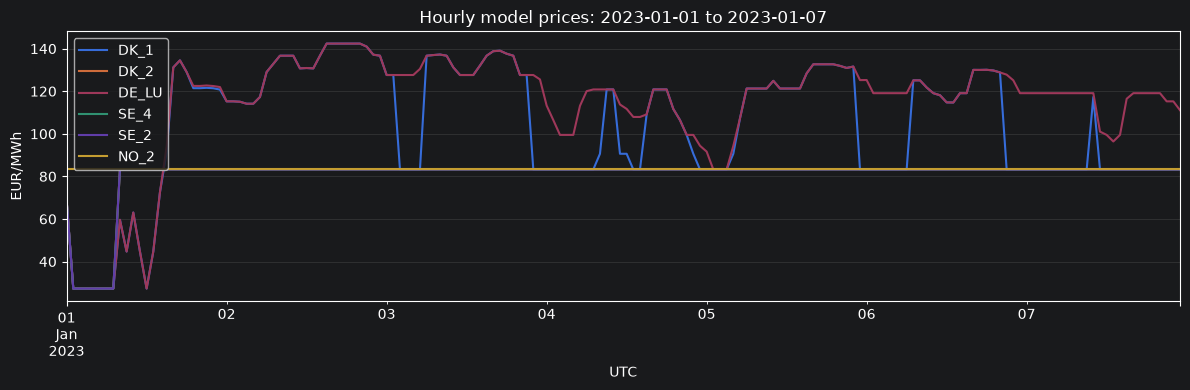

In [176]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

prices[selected].resample("MS").mean().plot(ax=axes[0], marker="o")
axes[0].set(title=f"{YEAR}: monthly mean model prices", ylabel="EUR/MWh", xlabel="UTC")

for zone in selected:
    ordered = prices[zone].dropna().sort_values(ascending=False).to_numpy()
    axes[1].plot(np.arange(1, len(ordered) + 1), ordered, label=zone)
axes[1].set(title="Model price duration curves", ylabel="EUR/MWh", xlabel="Hours, sorted")
axes[1].legend()
fig.tight_layout()
plt.show()

window = prices.loc[START:END, selected]
if window.empty:
    print("The selected date window is empty. Adjust START and END.")
else:
    ax = window.plot()
    ax.set(title=f"Hourly model prices: {START} to {END}", ylabel="EUR/MWh", xlabel="UTC")
    plt.tight_layout()
    plt.show()

## 4. Electricity supply and demand

The next chart includes **generator output and storage discharge**. Pumped storage and batteries recycle electricity, so their discharge must not be interpreted as additional primary generation. Charging is reported separately.

The plots use actual dispatch, not available renewable potential. Aggregation uses the model's snapshot weights. Load shedding is excluded from the supply mix and reported separately in section 7.

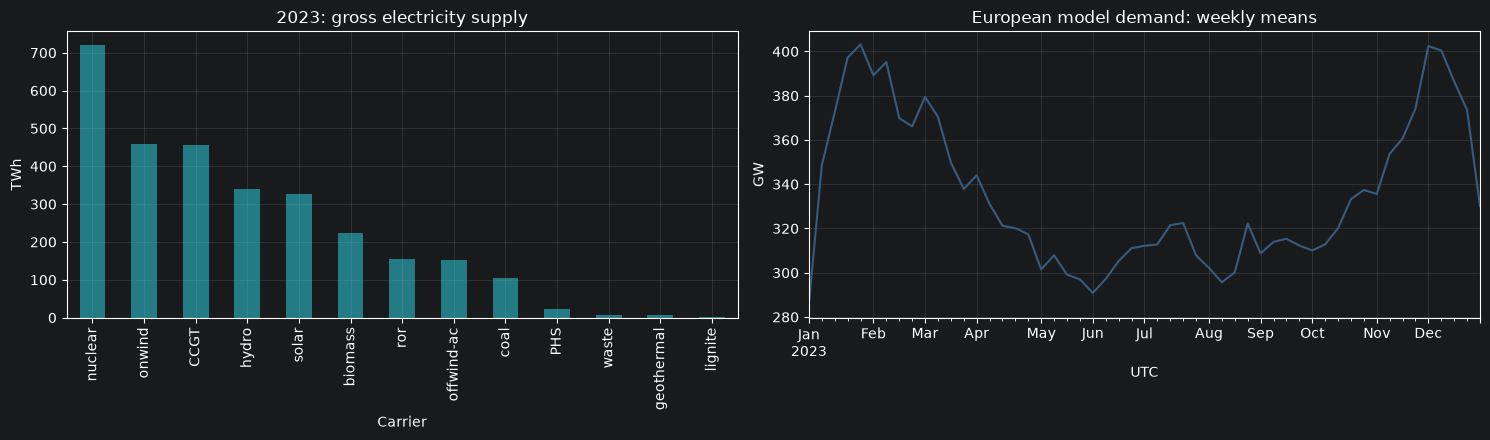

,Electricity supplied (TWh)
carrier,
nuclear,720.550
onwind,459.620
CCGT,455.109
hydro,339.174
solar,326.154
biomass,222.879
ror,154.400
offwind-ac,153.097
coal,105.207


,Discharge (TWh),Charging (TWh)
carrier,,
PHS,23.018,30.69
hydro,339.174,0.00


In [177]:
# Electricity buses come from the same complete zone mapping.
electricity_buses = [bus for buses in mapping.values() for bus in buses]
shedding_generators = n.generators.index[
    n.generators.carrier.str.contains("load|shedding", case=False, na=False)
]

def electric_supply_by_carrier(buses):
    generator_ids = n.generators.index[
        n.generators.bus.isin(buses) & ~n.generators.index.isin(shedding_generators)
    ]
    generator_output = n.generators_t.p.reindex(columns=generator_ids).mul(
        n.generators.loc[generator_ids, "sign"], axis=1
    )
    generator_output = generator_output.T.groupby(
        n.generators.loc[generator_ids, "carrier"]
    ).sum(min_count=1).T

    unit_ids = n.storage_units.index[n.storage_units.bus.isin(buses)]
    storage_output = n.storage_units_t.p_dispatch.reindex(columns=unit_ids)
    storage_output = storage_output.T.groupby(
        n.storage_units.loc[unit_ids, "carrier"]
    ).sum(min_count=1).T

    result = pd.concat([generator_output, storage_output], axis=1)
    result = result.T.groupby(level=0).sum(min_count=1).T
    result.index = prices.index
    return result

load_ids = n.loads.index[n.loads.bus.isin(electricity_buses)]
load_mw = n.get_switchable_as_dense("Load", "p_set")[load_ids].mul(
    -n.loads.loc[load_ids, "sign"], axis=1
)
load_by_bus = load_mw.T.groupby(n.loads.loc[load_ids, "bus"]).sum(min_count=1).T
load_by_bus.index = prices.index
demand = pd.DataFrame({
    zone: load_by_bus.reindex(columns=buses, fill_value=0).sum(axis=1, min_count=1)
    for zone, buses in mapping.items()
})

supply = electric_supply_by_carrier(electricity_buses)
generator_weights = pd.Series(
    n.snapshot_weightings.generators.to_numpy(), index=prices.index
)
annual_supply = supply.mul(generator_weights, axis=0).sum(min_count=1).div(1e6)
annual_supply = annual_supply[annual_supply.abs() > 1e-8].sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
annual_supply.plot.bar(ax=axes[0], color="#237b86")
axes[0].set(title=f"{YEAR}: gross electricity supply", ylabel="TWh", xlabel="Carrier")

demand.sum(axis=1, min_count=1).resample("W").mean().div(1e3).plot(ax=axes[1], color="#345c80")
axes[1].set(title="European model demand: weekly means", ylabel="GW", xlabel="UTC")
fig.tight_layout()
plt.show()
display(annual_supply.round(3).to_frame("Electricity supplied (TWh)"))

storage_ids = n.storage_units.index[n.storage_units.bus.isin(electricity_buses)]
storage_energy = pd.DataFrame({
    "Discharge (TWh)": n.storage_units_t.p_dispatch.reindex(columns=storage_ids)
        .mul(generator_weights.to_numpy(), axis=0).sum(min_count=1) / 1e6,
    "Charging (TWh)": n.storage_units_t.p_store.reindex(columns=storage_ids)
        .mul(generator_weights.to_numpy(), axis=0).sum(min_count=1) / 1e6,
})
display(storage_energy.groupby(n.storage_units.loc[storage_ids, "carrier"]).sum().round(3))

## 5. A closer look at the selected zone

Local generation does not have to equal local demand: inter-zone imports/exports, storage charging and losses also enter the balance. This is a visual inspection, not a full nodal-balance audit.

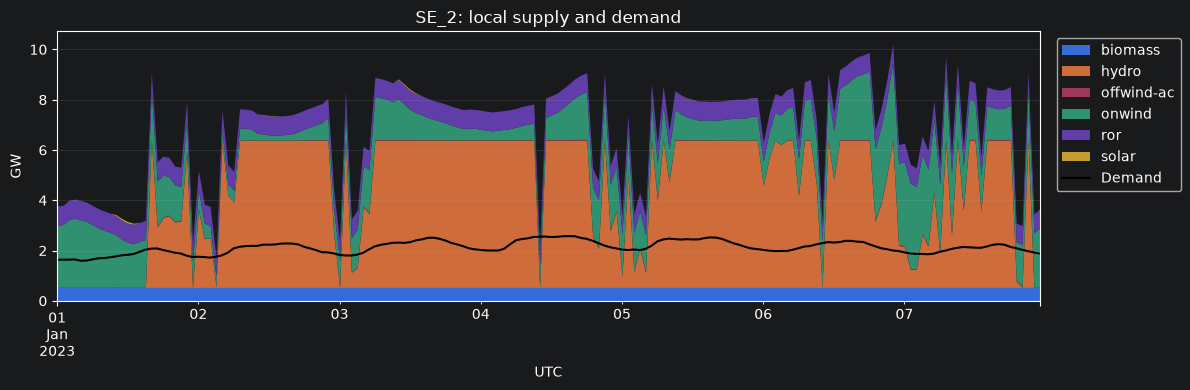

,Annual model demand (TWh)
DE_LU,463.080
FR,424.597
ES,226.504
GB,219.740
IT_NORD,169.294
PL,166.102
NL,109.396
SE_3,82.738
FI,78.946
BE,78.905


In [178]:
focus_supply = electric_supply_by_carrier(mapping[FOCUS_ZONE])
focus_window = focus_supply.loc[START:END].div(1e3)
active = focus_window.columns[focus_window.abs().sum() > 1e-8]

if focus_window.empty or len(active) == 0:
    print("No supply to plot in this date window.")
else:
    # Typical carriers here inject positive power. Plot signed output if a carrier
    # includes consumption, since a stacked positive-only chart would hide it.
    if focus_window[active].lt(-1e-8).any().any():
        ax = focus_window[active].plot()
    else:
        ax = focus_window[active].clip(lower=0).plot.area(linewidth=0)
    demand.loc[START:END, FOCUS_ZONE].div(1e3).plot(
        ax=ax, color="black", linewidth=1.5, label="Demand"
    )
    ax.set(title=f"{FOCUS_ZONE}: local supply and demand", ylabel="GW", xlabel="UTC")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.show()

display(demand.mul(generator_weights, axis=0).sum(min_count=1).div(1e6)
        .sort_values(ascending=False).round(3).to_frame("Annual model demand (TWh)"))

## 6. Flows across the selected zone's borders

**Positive means net export leaving FOCUS_ZONE; negative means net import.**

These are flows on the model's aggregated AC lines and DC links. They are not automatically equivalent to historical commercial exchanges or reconstructed market transfer capacities. The helper handles both branch orientations; internal copperplate links are excluded.

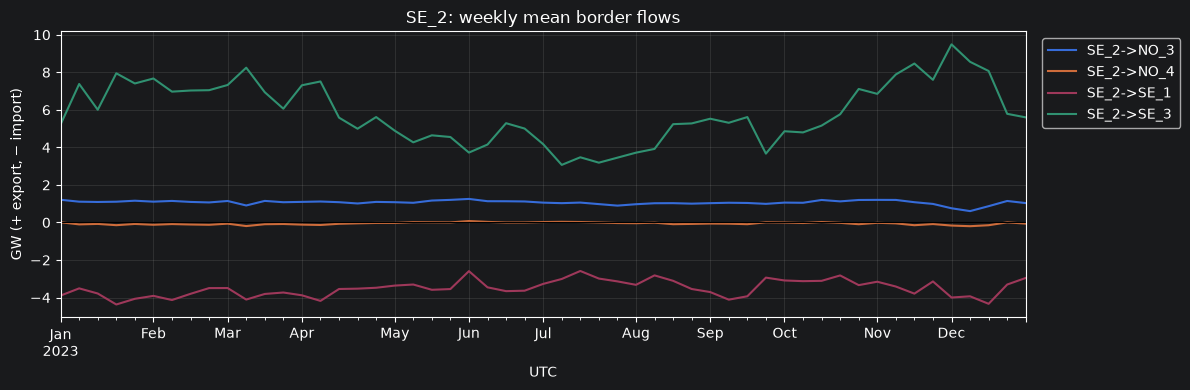

,Net export (TWh),Gross export (TWh),Gross import (TWh)
SE_2->NO_3,9.322,9.344,0.021
SE_2->NO_4,-0.495,0.361,0.856
SE_2->SE_1,-30.674,0.107,30.781
SE_2->SE_3,51.392,51.418,0.026


In [179]:
neighbours = sorted({
    b if a == FOCUS_ZONE else a
    for a, b in cfg["borders"] if FOCUS_ZONE in (a, b)
})
if not neighbours:
    focus_flows = pd.DataFrame(index=prices.index)
    print(f"{FOCUS_ZONE} has no mapped inter-zone AC/DC connections.")
else:
    focus_flows = border_flows(
        n, mapping, [(FOCUS_ZONE, neighbour) for neighbour in neighbours]
    )
    ax = focus_flows.resample("W").mean().div(1e3).plot()
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title=f"{FOCUS_ZONE}: weekly mean border flows",
           ylabel="GW (+ export, − import)", xlabel="UTC")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    plt.show()

    flow_summary = pd.DataFrame({
        "Net export (TWh)": focus_flows.mul(generator_weights, axis=0).sum(min_count=1) / 1e6,
        "Gross export (TWh)": focus_flows.clip(lower=0).mul(generator_weights, axis=0).sum(min_count=1) / 1e6,
        "Gross import (TWh)": -focus_flows.clip(upper=0).mul(generator_weights, axis=0).sum(min_count=1) / 1e6,
    })
    display(flow_summary.round(3))

## 7. Load shedding and storage levels

Load shedding is unmet demand represented by emergency supply components. The shared helper applies the generator sign, including the kW-to-MW convention used in some PyPSA files. A successful optimisation can still contain load shedding, which matters for interpreting price spikes.

The storage plot shows **state of charge**, not power output. StorageUnit energy is in MWh; the plot converts it to GWh.

,Model result
Unserved electricity (MWh),0.0
Hours above 1e-6 MW shedding,0.0
Maximum shedding (MW),0.0


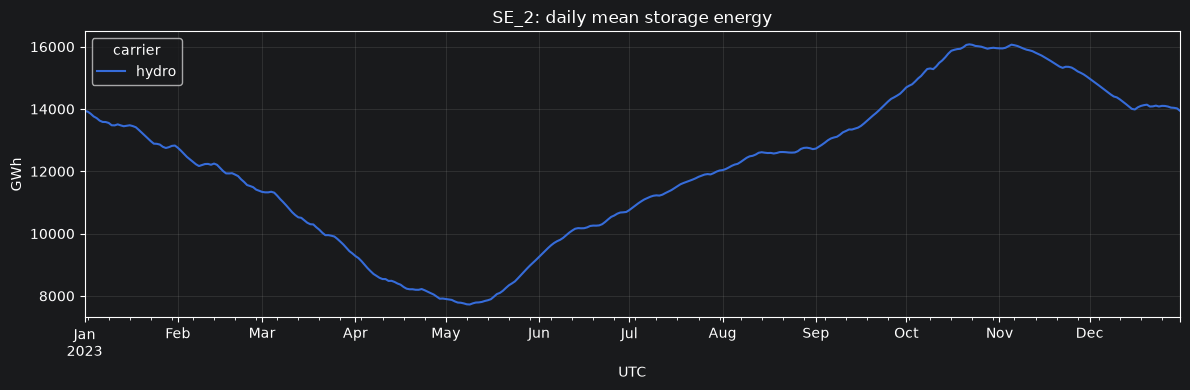

In [180]:
shedding = load_shedding(n)
shed_total = shedding.sum(axis=1)
display(pd.Series({
    "Unserved electricity (MWh)": float(shed_total.mul(generator_weights).sum()),
    "Hours above 1e-6 MW shedding": int(shed_total.gt(1e-6).sum()),
    "Maximum shedding (MW)": float(shed_total.max()),
}).to_frame("Model result"))

if shed_total.gt(1e-6).any():
    ax = shed_total.plot(color="#b54b3c")
    ax.set(title="Load shedding across the model", ylabel="MW", xlabel="UTC")
    plt.show()
    display(shedding.mul(generator_weights, axis=0).sum()
            .sort_values(ascending=False).head(15).to_frame("Unserved electricity (MWh)"))

focus_units = n.storage_units.index[n.storage_units.bus.isin(mapping[FOCUS_ZONE])]
if len(focus_units):
    soc = n.storage_units_t.state_of_charge.reindex(columns=focus_units)
    soc = soc.T.groupby(n.storage_units.loc[focus_units, "carrier"]).sum(min_count=1).T
    soc.index = prices.index
    ax = soc.resample("D").mean().div(1e3).plot()
    ax.set(title=f"{FOCUS_ZONE}: daily mean storage energy", ylabel="GWh", xlabel="UTC")
    plt.tight_layout()
    plt.show()
else:
    print(f"No StorageUnits in {FOCUS_ZONE}.")

## 8. Optional: first comparison with historical prices

This cell runs only if `data/hindcast/prices_zonal_YEAR.csv` is already available. It performs **no download** and does not fill missing observations. Model-only islands have no assigned reference.

If needed, retrieve the observation file separately from your **local terminal**:
```bash
pixi run python scripts/hindcast.py fetch-prices --years 2023
```
Use the year you selected above. The importer refuses to overwrite existing annual outputs.

The comparison below uses matched hourly observations. Both weekly curves use those same hours and require the configured coverage. An incomplete week can be omitted. The error table reports coverage so missing data are visible. For the full documented comparison across all zones, use `hindcast.py benchmark --year 2023` later.

,Status,Matched hours,Coverage (%),Bias (EUR/MWh),MAE (EUR/MWh),RMSE (EUR/MWh),Correlation
Zone,,,,,,,
DK_1,scored,8760,100.0,13.762,29.590,40.396,0.683
DK_2,scored,8760,100.0,-0.861,37.521,47.024,0.361
DE_LU,scored,8760,100.0,8.586,26.180,37.058,0.719
SE_4,scored,8760,100.0,15.500,42.634,50.316,0.336
SE_2,scored,8760,100.0,40.089,45.938,51.638,0.308
NO_2,scored,8760,100.0,2.996,26.112,35.189,0.294


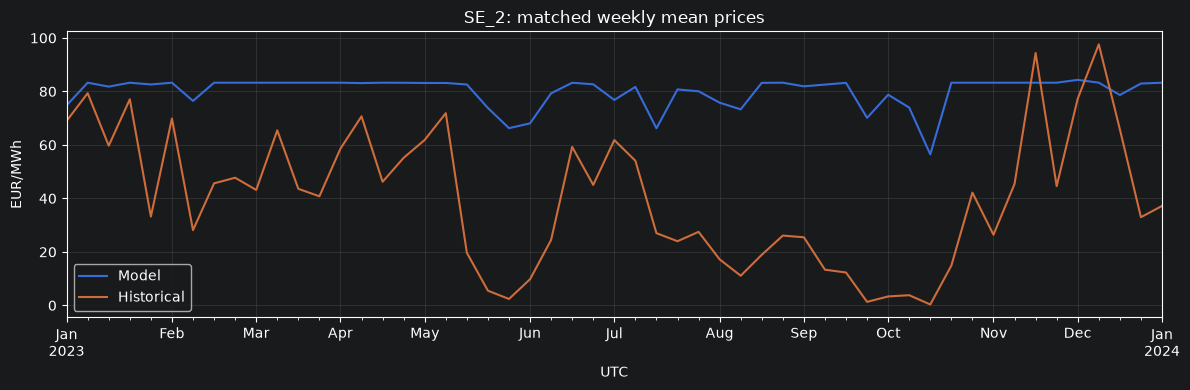

In [181]:
OBSERVED = PROJECT_ROOT / cfg["prices"]
if not OBSERVED.is_file():
    print(f"Historical-price comparison skipped: {OBSERVED.name} is not available.")
    print("All preceding sections work without it.")
else:
    observed = reference_prices(
        read_hourly(OBSERVED),
        read_hourly(cfg["loads"]) if cfg.get("loads") else None,
        cfg["regions"],
    )
    rows = []
    for zone in selected:
        reason = cfg["regions"][zone].get("unscored_reason")
        if reason:
            rows.append({"Zone": zone, "Status": "NOT SCORED: " + reason})
            continue
        try:
            scores, _ = paired_metrics(prices[zone], observed[zone])
        except ValueError as exc:
            if str(exc) != "No valid matched observations at requested resolution":
                raise
            rows.append({"Zone": zone, "Status": "NOT SCORED: no paired observations"})
            continue
        rows.append({
            "Zone": zone,
            "Status": "scored",
            "Matched hours": scores["n_matched_hours"],
            "Coverage (%)": 100 * scores["coverage"],
            "Bias (EUR/MWh)": scores["bias"],  # Model minus observed.
            "MAE (EUR/MWh)": scores["mae"],
            "RMSE (EUR/MWh)": scores["rmse"],
            "Correlation": scores["correlation"],
        })
    display(pd.DataFrame(rows).set_index("Zone").round(3))

    reason = cfg["regions"][FOCUS_ZONE].get("unscored_reason")
    if reason:
        print(f"{FOCUS_ZONE}: {reason}")
    else:
        try:
            _, weekly_pair = paired_metrics(
                prices[FOCUS_ZONE], observed[FOCUS_ZONE], frequency="weekly",
                min_coverage=cfg.get("min_aggregate_coverage", 1.0),
            )
        except ValueError as exc:
            if str(exc) != "No valid matched observations at requested resolution":
                raise
            print(f"No sufficiently complete paired weeks for {FOCUS_ZONE}.")
        else:
            ax = weekly_pair.rename(columns={"model": "Model", "observed": "Historical"}).plot()
            ax.set(title=f"{FOCUS_ZONE}: matched weekly mean prices",
                   ylabel="EUR/MWh", xlabel="UTC")
            plt.tight_layout()
            plt.show()

## 9. Diagnostic setup and annual asset inventory

Run sections 1–8 first, then continue here. All new tables refer to `n`, the **existing solution** you loaded. No model is built or optimised.

The national plant fleet and spatial allocation are separate questions. The inventory below helps identify where generation, storage and demand were placed. Generator capacity excludes load-shedding components; storage power and reservoir energy are reported separately.

The numerical proximity thresholds at the top of the notebook are **diagnostic thresholds**, not solver settings. They never change the network.

In [182]:
diag_zones = list(dict.fromkeys([FOCUS_ZONE, *[zone for zone in DIAG_ZONES if zone in mapping]]))
if not diag_zones:
    raise ValueError("None of DIAG_ZONES occurs in the loaded mapping.")
if PRICE_BIN_WIDTH <= 0 or not 0 <= SOC_BOUND_RTOL < 0.5:
    raise ValueError("Use a positive PRICE_BIN_WIDTH and 0 <= SOC_BOUND_RTOL < 0.5.")
if PRICE_MATCH_ATOL < 0 or POWER_BOUND_RTOL < 0:
    raise ValueError("Diagnostic proximity tolerances must be non-negative.")

zone_of_bus = {bus: zone for zone, buses in mapping.items() for bus in buses}
weights = pd.Series(n.snapshot_weightings.generators.to_numpy(), index=prices.index)
water_weights = pd.Series(n.snapshot_weightings.stores.to_numpy(), index=prices.index)

def dense_input(component, attribute, ids):
    """Include static defaults as well as any exported hourly input overrides."""
    frame = n.get_switchable_as_dense(component, attribute).reindex(columns=ids).copy()
    frame.index = prices.index
    return frame

def output_series(table, attribute, ids):
    """Read solved outputs; missing exported values stay missing."""
    frame = getattr(n, table + "_t")[attribute].reindex(columns=ids).copy()
    frame.index = prices.index
    return frame

def masked_percent(condition, valid):
    denominator = valid.sum().replace(0, np.nan)
    return 100 * (condition & valid).sum() / denominator

gmeta = n.generators.loc[
    n.generators.bus.map(zone_of_bus).isin(diag_zones)
    & ~n.generators.index.isin(shedding_generators)
    & n.generators.p_nom.gt(0)
].copy()
gmeta["zone"] = gmeta.bus.map(zone_of_bus)
smeta = n.storage_units.loc[
    n.storage_units.bus.map(zone_of_bus).isin(diag_zones)
    & n.storage_units.p_nom.gt(0)
].copy()
smeta["zone"] = smeta.bus.map(zone_of_bus)

capacity_gw = gmeta.groupby(["zone", "carrier"]).p_nom.sum().unstack(fill_value=0) / 1e3
display(capacity_gw.reindex(diag_zones).fillna(0).round(3).rename_axis(
    index="Zone", columns="Generator capacity (GW)"
))
display((smeta.groupby(["zone", "carrier"]).p_nom.sum().unstack(fill_value=0) / 1e3)
        .round(3).rename_axis(index="Zone", columns="StorageUnit power (GW)"))
display(demand[diag_zones].mul(weights, axis=0).sum(min_count=1).div(1e6)
        .round(3).to_frame("Annual model demand (TWh)"))

revision_file = NETWORK.parent / "submitted-revision.txt"
if revision_file.is_file():
    print("Revision recorded at solve submission:", revision_file.read_text().strip())
print("Inspecting network:", NETWORK)
print("These tables describe the saved solution, including any original allocation errors.")

Generator capacity (GW),CCGT,OCGT,biomass,coal,geothermal,lignite,nuclear,offwind-ac,oil,onwind,ror,solar,waste
Zone,,,,,,,,,,,,,
SE_2,0.000,0.000,0.539,0.000,0.000,0.000,0.000,0.030,0.000,4.857,1.756,0.315,0.077
DK_1,0.775,0.000,0.661,2.480,0.000,0.000,0.000,1.493,0.000,3.808,0.000,2.691,0.051
DK_2,0.376,0.000,1.120,0.000,0.000,0.000,0.000,0.976,0.126,0.999,0.000,0.838,0.102
SE_1,0.100,0.000,0.088,0.000,0.000,0.000,0.000,0.031,0.000,2.968,0.140,0.563,0.000
SE_3,0.250,0.000,2.118,0.000,0.000,0.000,7.184,0.096,1.999,6.011,0.327,2.202,0.334
SE_4,0.440,0.000,0.441,0.000,0.000,0.000,0.000,0.036,1.110,2.195,0.000,0.914,0.042
NO_1,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.616,1.489,0.077,0.000
NO_2,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.240,0.074,0.000
NO_3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.001,0.000,0.966,0.080,0.139,0.000


StorageUnit power (GW),PHS,hydro
Zone,,
DE_LU,9.073,0.398
FI,0.000,1.568
NO_1,0.000,2.762
NO_2,0.000,11.184
NO_3,0.061,4.334
NO_4,0.000,5.163
NO_5,0.091,7.592
SE_1,0.000,5.035
SE_2,0.000,5.855


,Annual model demand (TWh)
SE_2,15.486
DK_1,17.299
DK_2,17.182
SE_1,7.574
SE_3,82.738
SE_4,24.821
NO_1,41.873
NO_2,34.413
NO_3,24.639
NO_4,20.867


Revision recorded at solve submission: d3e54e22c94ff91d2763d79a222172ba718ff14b
Inspecting network: /home/tom/PycharmProjects/pypsa-eur/results/hindcast-corrected-2023/network.nc
These tables describe the saved solution, including any original allocation errors.


## 10. Is the model missing price variation or regional separation?

The first table compares **hourly variation on matched observations**, where historical prices exist. Standard deviation and P95–P05 measure the range; the mean absolute hour-to-hour change measures short-term movement. The latter uses only consecutive UTC hours.

The concentration column is the share of valid model hours in the most common rounded price bin. Its value depends on `PRICE_BIN_WIDTH`; it is not a count of exactly identical prices.

The matrices show model correlation and the percentage of matched model hours with prices within `PRICE_MATCH_ATOL`. Similar prices alone do not prove excessive grid capacity: shared fuel costs, storage opportunity costs and other constraints can also matter.

,Model valid hours,Most common bin (EUR/MWh),Hours in that bin (%),Reference,Hours used,Coverage (%),Model mean,Model std,Model P95-P05,Model mean hourly change,Model negative hours (%),Historical mean,Historical std,Historical P95-P05,Historical mean hourly change,Historical negative hours (%)
Zone,,,,,,,,,,,,,,,,
SE_2,8760,83.0,89.429,matched hourly observations,8760,100.0,80.069,12.237,22.321,0.851,0.0,39.980,34.160,102.410,3.470,4.954
DK_1,8760,83.0,18.174,matched hourly observations,8760,100.0,100.590,20.304,56.162,2.709,0.0,86.828,48.821,161.651,9.861,3.208
DK_2,8760,83.0,88.162,matched hourly observations,8760,100.0,80.396,12.921,20.816,1.031,0.0,81.257,50.117,161.450,10.235,2.637
SE_1,8760,83.0,89.406,matched hourly observations,8760,100.0,80.051,12.294,21.516,0.855,0.0,39.975,34.163,102.410,3.471,4.954
SE_3,8760,83.0,89.384,matched hourly observations,8760,100.0,80.065,12.248,20.816,0.836,0.0,51.705,45.324,139.910,6.688,4.897
SE_4,8760,83.0,88.311,matched hourly observations,8760,100.0,80.382,12.844,20.816,1.009,0.0,64.882,50.635,155.811,9.271,4.201
NO_1,8760,83.0,94.623,matched hourly observations,8760,100.0,82.437,5.509,0.859,0.379,0.0,66.944,44.678,135.821,4.203,4.349
NO_2,8760,83.0,94.852,matched hourly observations,8760,100.0,82.436,5.504,0.878,0.377,0.0,79.439,36.284,129.624,5.066,1.986
NO_3,8760,83.0,94.475,matched hourly observations,8760,100.0,82.405,5.535,1.442,0.403,0.0,38.556,32.794,99.241,2.742,4.578


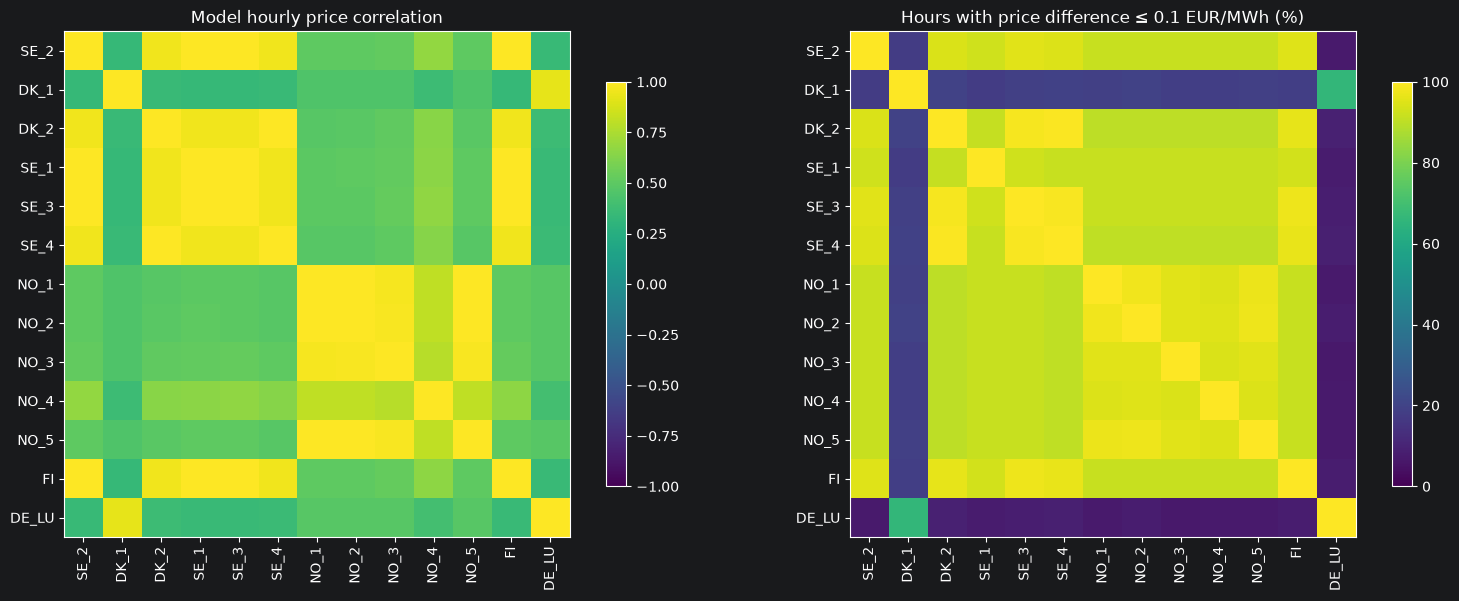

,SE_2,DK_1,DK_2,SE_1,SE_3,SE_4,NO_1,NO_2,NO_3,NO_4,NO_5,FI,DE_LU
SE_2,100.0,17.9,94.1,92.7,95.6,94.5,91.6,91.6,91.6,91.6,91.6,95.2,7.4
DK_1,17.9,100.0,19.6,17.9,19.1,19.4,18.8,19.8,18.5,18.5,18.8,18.6,66.3
DK_2,94.1,19.6,100.0,91.4,98.5,99.5,90.1,90.1,90.2,90.1,90.1,96.1,9.0
SE_1,92.7,17.9,91.4,100.0,92.9,91.8,91.5,91.5,91.5,91.6,91.5,93.2,7.4
SE_3,95.6,19.1,98.5,92.9,100.0,98.9,91.6,91.6,91.6,91.5,91.6,97.6,8.5
SE_4,94.5,19.4,99.5,91.8,98.9,100.0,90.5,90.5,90.5,90.5,90.5,96.6,8.7
NO_1,91.6,18.8,90.1,91.5,91.6,90.5,100.0,97.8,95.5,94.9,97.2,91.5,7.3
NO_2,91.6,19.8,90.1,91.5,91.6,90.5,97.8,100.0,95.5,95.3,97.6,91.5,8.1
NO_3,91.6,18.5,90.2,91.5,91.6,90.5,95.5,95.5,100.0,94.1,95.5,91.6,7.0
NO_4,91.6,18.5,90.1,91.6,91.5,90.5,94.9,95.3,94.1,100.0,94.7,91.6,7.1


In [183]:
observed_diag = None
observed_path = PROJECT_ROOT / cfg["prices"]
if observed_path.is_file():
    observed_diag = reference_prices(
        read_hourly(observed_path),
        read_hourly(cfg["loads"]) if cfg.get("loads") else None,
        cfg["regions"],
    )

variation_rows = []
consecutive = prices.index.to_series().diff().eq(pd.Timedelta(hours=1))
for zone in diag_zones:
    model = prices[zone].replace([np.inf, -np.inf], np.nan)
    rounded = (model.dropna() / PRICE_BIN_WIDTH).round() * PRICE_BIN_WIDTH
    row = {
        "Zone": zone,
        "Model valid hours": model.notna().sum(),
        "Most common bin (EUR/MWh)": rounded.mode().iloc[0] if len(rounded) else np.nan,
        "Hours in that bin (%)": 100 * rounded.value_counts(normalize=True).max()
            if len(rounded) else np.nan,
    }
    has_reference = (
        observed_diag is not None
        and not cfg["regions"][zone].get("unscored_reason")
    )
    pair = pd.DataFrame({"Model": model})
    if has_reference:
        pair["Historical"] = observed_diag[zone].reindex(model.index)
        pair = pair.replace([np.inf, -np.inf], np.nan).dropna()
        row["Reference"] = "matched hourly observations"
    else:
        pair = pair.dropna()
        row["Reference"] = "model only; no historical comparison"
    row["Hours used"] = len(pair)
    row["Coverage (%)"] = 100 * len(pair) / len(model)
    for label in pair:
        series = pair[label]
        # Reindex before differencing so a gap is never treated as one hour.
        hourly_change = series.reindex(prices.index).diff().abs().where(consecutive)
        row[f"{label} mean"] = series.mean()
        row[f"{label} std"] = series.std()
        row[f"{label} P95-P05"] = series.quantile(0.95) - series.quantile(0.05)
        row[f"{label} mean hourly change"] = hourly_change.mean()
        row[f"{label} negative hours (%)"] = 100 * series.lt(0).mean() if len(series) else np.nan
    variation_rows.append(row)

price_variation = pd.DataFrame(variation_rows).set_index("Zone")
display(price_variation.round(3))

model_corr = prices[diag_zones].corr()
equal_price_hours = pd.DataFrame(index=diag_zones, columns=diag_zones, dtype=float)
for a in diag_zones:
    for b in diag_zones:
        valid = prices[a].notna() & prices[b].notna()
        equal_price_hours.loc[a, b] = (
            100 * prices.loc[valid, a].sub(prices.loc[valid, b]).abs()
                .le(PRICE_MATCH_ATOL).mean()
            if valid.any() else np.nan
        )

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, frame, title, vmin, vmax in [
    (axes[0], model_corr, "Model hourly price correlation", -1, 1),
    (axes[1], equal_price_hours, f"Hours with price difference ≤ {PRICE_MATCH_ATOL:g} EUR/MWh (%)", 0, 100),
]:
    im = ax.imshow(frame.to_numpy(), vmin=vmin, vmax=vmax, cmap="viridis")
    ax.set_xticks(range(len(frame)), frame.columns, rotation=90)
    ax.set_yticks(range(len(frame)), frame.index)
    ax.set_title(title)
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()
display(equal_price_hours.round(1))

## 11. Generator costs, availability and price-setting candidates

These tables read the marginal costs **already stored in the network**, including native fuel/CO2 inputs. They do not reconstruct or adjust generator costs.

An output between its lower and upper dispatch bounds, with a marginal cost close to the local price, is a **candidate** for marginal price-setting. This is not proof: ramping, commitment, quadratic costs or other constraints can alter that relationship. Multiple units or carriers can qualify in the same hour; the percentages must not be summed as a market-share decomposition.

For a generator at its upper bound, matching its cost to the price is not enough to identify it as marginal. Conversely, a hydro water value or an import can set the local opportunity cost even when no local generator qualifies.

In [184]:
gp = output_series("generators", "p", gmeta.index)
gmax = dense_input("Generator", "p_max_pu", gmeta.index)
gmin = dense_input("Generator", "p_min_pu", gmeta.index)
gcost = dense_input("Generator", "marginal_cost", gmeta.index)
gupper = gmax.mul(gmeta.p_nom, axis=1)
glower = gmin.mul(gmeta.p_nom, axis=1)
gtol = (gmeta.p_nom * POWER_BOUND_RTOL).clip(lower=0.01)
gvalid = gp.notna() & gupper.notna() & glower.notna()
gflexible = gvalid & (gupper - glower).gt(gtol, axis=1)
ginterior = (
    gflexible
    & gp.sub(glower).gt(gtol, axis=1)
    & gupper.sub(gp).gt(gtol, axis=1)
)
local_generator_price = pd.DataFrame(
    {name: prices[gmeta.at[name, "zone"]] for name in gmeta.index},
    index=prices.index,
)

# Candidate calculation is restricted to standard sign=1 generators.
standard_sign = gmeta["sign"].eq(1)
gmatch_valid = gvalid & gcost.notna() & local_generator_price.notna()
gmatch = (
    ginterior
    & local_generator_price.sub(gcost).abs().le(PRICE_MATCH_ATOL)
).mul(standard_sign, axis=1).astype(bool)

generator_diagnostics = gmeta[["zone", "bus", "carrier", "p_nom", "efficiency"]].copy()
generator_diagnostics["Availability min"] = gmax.min()
generator_diagnostics["Availability max"] = gmax.max()
generator_diagnostics["Availability std"] = gmax.std()
generator_diagnostics["Marginal cost min"] = gcost.min()
generator_diagnostics["Marginal cost mean"] = gcost.mean()
generator_diagnostics["Marginal cost max"] = gcost.max()
generator_diagnostics["Capacity factor"] = gp.mul(weights, axis=0).sum(min_count=1) / (
    gmeta.p_nom * weights.sum()
)
generator_diagnostics["At upper bound (%)"] = masked_percent(
    gflexible & gupper.sub(gp).abs().le(gtol, axis=1), gflexible
)
generator_diagnostics["At lower bound (%)"] = masked_percent(
    gflexible & gp.sub(glower).abs().le(gtol, axis=1), gflexible
)
generator_diagnostics["Interior dispatch (%)"] = masked_percent(ginterior, gvalid)
generator_diagnostics["Interior & price-match (%)"] = masked_percent(gmatch, gmatch_valid)
generator_diagnostics["Valid output hours"] = gvalid.sum()
generator_diagnostics["Committable"] = gmeta.committable

# Start with technologies relevant to the flat Nordic curves.
focus_carriers = ["biomass", "nuclear", "CCGT", "OCGT", "coal", "lignite"]
display(generator_diagnostics.loc[
    generator_diagnostics.carrier.isin(focus_carriers)
].sort_values(["zone", "carrier"]).round(4))

candidate_rows = []
for zone in diag_zones:
    ids = gmeta.index[gmeta.zone.eq(zone) & standard_sign]
    if not len(ids):
        continue
    valid_hours = local_generator_price[ids].notna().any(axis=1) & gvalid[ids].any(axis=1)
    for carrier, group in gmeta.loc[ids].groupby("carrier"):
        qualifies = gmatch[group.index].any(axis=1)
        candidate_rows.append({
            "Zone": zone, "Carrier": carrier,
            "Hours with ≥1 interior price-match candidate": int((qualifies & valid_hours).sum()),
            "Model hours with valid price/output": int(valid_hours.sum()),
            "Candidate hours (%)": 100 * qualifies[valid_hours].mean()
                if valid_hours.any() else np.nan,
        })
candidate_summary = pd.DataFrame(candidate_rows)
display(candidate_summary.sort_values(
    ["Zone", "Candidate hours (%)"], ascending=[True, False]
).round(2) if len(candidate_summary) else candidate_summary)

,zone,bus,carrier,p_nom,efficiency,Availability min,Availability max,Availability std,Marginal cost min,Marginal cost mean,Marginal cost max,Capacity factor,At upper bound (%),At lower bound (%),Interior dispatch (%),Interior & price-match (%),Valid output hours,Committable
name,,,,,,,,,,,,,,,,,,
DE00 CCGT,DE_LU,DE00,CCGT,32449.0287,0.5231,1.000,1.000,0.0,79.9211,117.1309,183.4242,0.0777,1.3813,82.9795,15.6393,15.6393,8760,False
DE00 OCGT,DE_LU,DE00,OCGT,7113.7653,0.3906,1.000,1.000,0.0,105.1868,155.0266,243.8214,0.0000,0.0000,100.0000,0.0000,0.0000,8760,False
DE00 biomass,DE_LU,DE00,biomass,7985.5792,0.4648,1.000,1.000,0.0,20.1187,20.1187,20.1187,0.9974,99.6005,0.1826,0.2169,0.2169,8760,False
LUG1 biomass,DE_LU,LUG1,biomass,2.8000,0.4680,1.000,1.000,0.0,19.9799,19.9799,19.9799,0.9984,99.8402,0.1598,0.0000,0.0000,8760,False
DE00 coal,DE_LU,DE00,coal,23743.1840,0.3919,1.000,1.000,0.0,95.6363,113.9228,142.3833,0.2743,21.5639,66.8721,11.5639,11.5639,8760,False
DE00 lignite,DE_LU,DE00,lignite,19626.5630,0.3708,1.000,1.000,0.0,109.6276,132.0290,158.5564,0.0112,0.7877,98.4932,0.7192,0.7192,8760,False
DE00 nuclear,DE_LU,DE00,nuclear,4056.0000,0.3300,0.714,0.714,0.0,27.0457,27.0457,27.0457,0.7078,98.9840,0.7078,0.3082,0.3082,8760,False
DKW1 CCGT,DK_1,DKW1,CCGT,775.2000,0.5600,1.000,1.000,0.0,75.0473,109.8079,171.7376,0.2716,23.9840,69.9087,6.1073,6.1073,8760,False
DKW1 biomass,DK_1,DKW1,biomass,661.0000,0.4680,1.000,1.000,0.0,19.9799,19.9799,19.9799,0.9984,99.8402,0.1598,0.0000,0.0000,8760,False


,Zone,Carrier,Hours with ≥1 interior price-match candidate,Model hours with valid price/output,Candidate hours (%)
73,DE_LU,CCGT,1370,8760,15.64
76,DE_LU,coal,1013,8760,11.56
85,DE_LU,waste,108,8760,1.23
78,DE_LU,lignite,63,8760,0.72
79,DE_LU,nuclear,27,8760,0.31
...,...,...,...,...,...
36,SE_4,biomass,0,8760,0.00
37,SE_4,offwind-ac,0,8760,0.00
38,SE_4,oil,0,8760,0.00
39,SE_4,onwind,0,8760,0.00


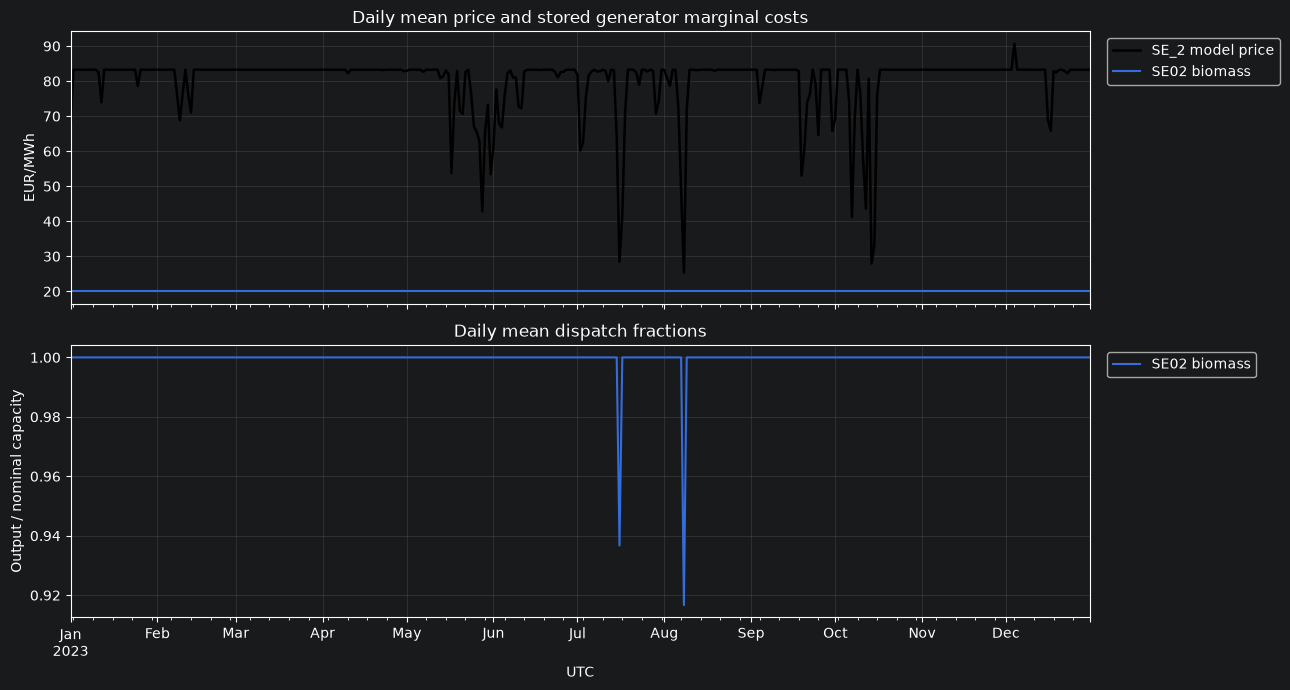

In [185]:
cost_plot_ids = gmeta.index[
    gmeta.zone.eq(FOCUS_ZONE) & gmeta.carrier.isin(focus_carriers)
][:8]
if len(cost_plot_ids):
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    prices[FOCUS_ZONE].resample("D").mean().plot(
        ax=axes[0], color="black", linewidth=1.8, label=f"{FOCUS_ZONE} model price"
    )
    for name in cost_plot_ids:
        gcost[name].resample("D").mean().plot(ax=axes[0], label=name)
    axes[0].set(ylabel="EUR/MWh", title="Daily mean price and stored generator marginal costs")
    axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1))

    gp[cost_plot_ids].div(gmeta.loc[cost_plot_ids, "p_nom"], axis=1).resample("D").mean().plot(ax=axes[1])
    axes[1].set(ylabel="Output / nominal capacity", xlabel="UTC", title="Daily mean dispatch fractions")
    axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    plt.show()
else:
    print(f"No selected thermal carriers in {FOCUS_ZONE}; use the hydro and border diagnostics.")

## 12. Are the inter-zone branches constraining trade?

The table inspects each **AC line or DC link individually**, including its exported hourly rating inputs. Infinite internal market links are excluded.

- Bound proximity uses the branch's directional MW limits, with tolerance `max(0.01 MW, POWER_BOUND_RTOL × nominal MW)`.
- A link sitting at its zero-flow lower bound is not counted as an export/import congestion event.
- Bound percentages are conditional on hours when the branch can carry flow; fully closed hours are reported separately.
- A branch close to a bound is a **candidate binding constraint**, not proof of a positive congestion shadow price.
- Directional utilisation is based on signed `p0`; a value above 100% should be investigated, not clipped.
- Raw price differences can also reflect losses or other constraints. Do not interpret the sum of physical branch ratings as historical NTC or flow-based market capacity.

Use the rows around SE2–SE3, SE3–SE4, DK2–SE4, DK1–DK2 and the German interconnectors first.

In [186]:
branch_rows = []
branch_loading = {}
branch_flow = {}
branch_details = {}

for component, table_name, nominal_attr in [
    ("Line", "lines", "s_nom"), ("Link", "links", "p_nom")
]:
    table = getattr(n, table_name)
    zone0 = table.bus0.map(zone_of_bus)
    zone1 = table.bus1.map(zone_of_bus)
    keep = (
        zone0.notna() & zone1.notna() & zone0.ne(zone1)
        & (zone0.isin(diag_zones) | zone1.isin(diag_zones))
        & table[nominal_attr].gt(0) & np.isfinite(table[nominal_attr])
    )
    if component == "Link":
        keep &= table.carrier.eq("DC")
    ids = table.index[keep]
    if not len(ids):
        continue
    flows = output_series(table_name, "p0", ids)
    if component == "Line":
        upper = dense_input(component, "s_max_pu", ids).mul(table.loc[ids, nominal_attr], axis=1)
        lower = -upper
    else:
        upper = dense_input(component, "p_max_pu", ids).mul(table.loc[ids, nominal_attr], axis=1)
        lower = dense_input(component, "p_min_pu", ids).mul(table.loc[ids, nominal_attr], axis=1)

    for name in ids:
        key = f"{component}: {name}"
        flow, hi, lo = flows[name], upper[name], lower[name]
        tol = max(0.01, POWER_BOUND_RTOL * float(table.at[name, nominal_attr]))
        valid = np.isfinite(flow) & np.isfinite(hi) & np.isfinite(lo)
        opened = valid & hi.sub(lo).gt(tol)
        at_upper = opened & hi.gt(tol) & flow.sub(hi).abs().le(tol)
        at_lower = opened & lo.lt(-tol) & flow.sub(lo).abs().le(tol)
        denominator = hi.where(flow.ge(0), -lo)
        utilisation = flow.abs().div(denominator.where(denominator.gt(tol))).where(valid)
        a, b = zone0.at[name], zone1.at[name]
        spread = prices[a].sub(prices[b]).abs()
        paired = valid & spread.notna()
        at_bound = at_upper | at_lower

        branch_rows.append({
            "Branch": key, "Zone 0": a, "Zone 1": b,
            "Nominal MW": table.at[name, nominal_attr],
            "Mean upper limit MW": hi[valid].mean(),
            "Mean lower limit MW": lo[valid].mean(),
            "Closed both directions (%)": 100 * (~opened & valid).sum() / valid.sum()
                if valid.any() else np.nan,
            "At nonzero upper bound (%)": 100 * at_upper[opened].mean()
                if opened.any() else np.nan,
            "At nonzero lower bound (%)": 100 * at_lower[opened].mean()
                if opened.any() else np.nan,
            "Mean directional utilisation (%)": 100 * utilisation.mean(),
            "Max directional utilisation (%)": 100 * utilisation.max(),
            "Mean absolute zone spread (EUR/MWh)": spread[paired].mean(),
            "Price-separated hours (%)": 100 * spread[paired].gt(PRICE_MATCH_ATOL).mean()
                if paired.any() else np.nan,
            "Spread when near bound (EUR/MWh)": spread[paired & at_bound].mean(),
            "Valid flow/limit hours": int(valid.sum()),
        })
        branch_loading[key] = utilisation
        branch_flow[key] = flow
        branch_details[key] = (a, b)

branch_diagnostics = pd.DataFrame(branch_rows)
if len(branch_diagnostics):
    branch_diagnostics = branch_diagnostics.set_index("Branch")
    display(branch_diagnostics.sort_values(
        "Mean absolute zone spread (EUR/MWh)", ascending=False
    ).round(3))
    loading_by_branch = pd.DataFrame(branch_loading)
else:
    loading_by_branch = pd.DataFrame(index=prices.index)
    print("No finite-rated inter-zone AC lines/DC links found for the diagnostic zones.")

,Zone 0,Zone 1,Nominal MW,Mean upper limit MW,Mean lower limit MW,Closed both directions (%),At nonzero upper bound (%),At nonzero lower bound (%),Mean directional utilisation (%),Max directional utilisation (%),Mean absolute zone spread (EUR/MWh),Price-separated hours (%),Spread when near bound (EUR/MWh),Valid flow/limit hours
Branch,,,,,,,,,,,,,,
Link: relation/3392010-450-DC,PL,SE_4,600.000,600.000,-600.000,0.0,0.582,98.642,99.604,100.000,31.288,97.854,31.532,8760
Link: relation/6886400-450-DC,EE,FI,650.000,650.000,-650.000,0.0,0.342,99.053,99.679,100.000,30.248,97.386,30.432,8760
Link: relation/8184630-150-DC,EE,FI,350.000,350.000,-350.000,0.0,0.342,99.292,99.833,100.000,30.248,97.386,30.359,8760
Link: relation/8185455-300-DC,LT,SE_4,700.000,700.000,-700.000,0.0,0.126,99.212,99.707,100.000,29.951,97.260,30.151,8760
Link: relation/13295785-515-DC,NO_2,GB,1400.000,1400.000,-1400.000,0.0,73.402,20.011,96.704,100.000,24.945,88.642,26.704,8760
Link: relation/3918230-450-DC,DE_LU,SE_4,600.000,600.000,-600.000,0.0,6.724,92.226,99.488,100.000,24.642,91.267,24.903,8760
Link: relation/2505320-400-DC,DK_2,DE_LU,600.000,600.000,-600.000,0.0,94.075,4.441,99.296,100.000,24.605,91.005,24.976,8760
Link: relation/9965201-450-DC,NL,NO_2,700.000,700.000,-700.000,0.0,8.938,89.144,99.047,100.000,23.692,94.543,24.156,8760
Link: relation/16213216-525-DC,DE_LU,NO_2,1400.000,1400.000,-1400.000,0.0,9.018,87.660,98.304,100.000,23.054,91.941,23.846,8760


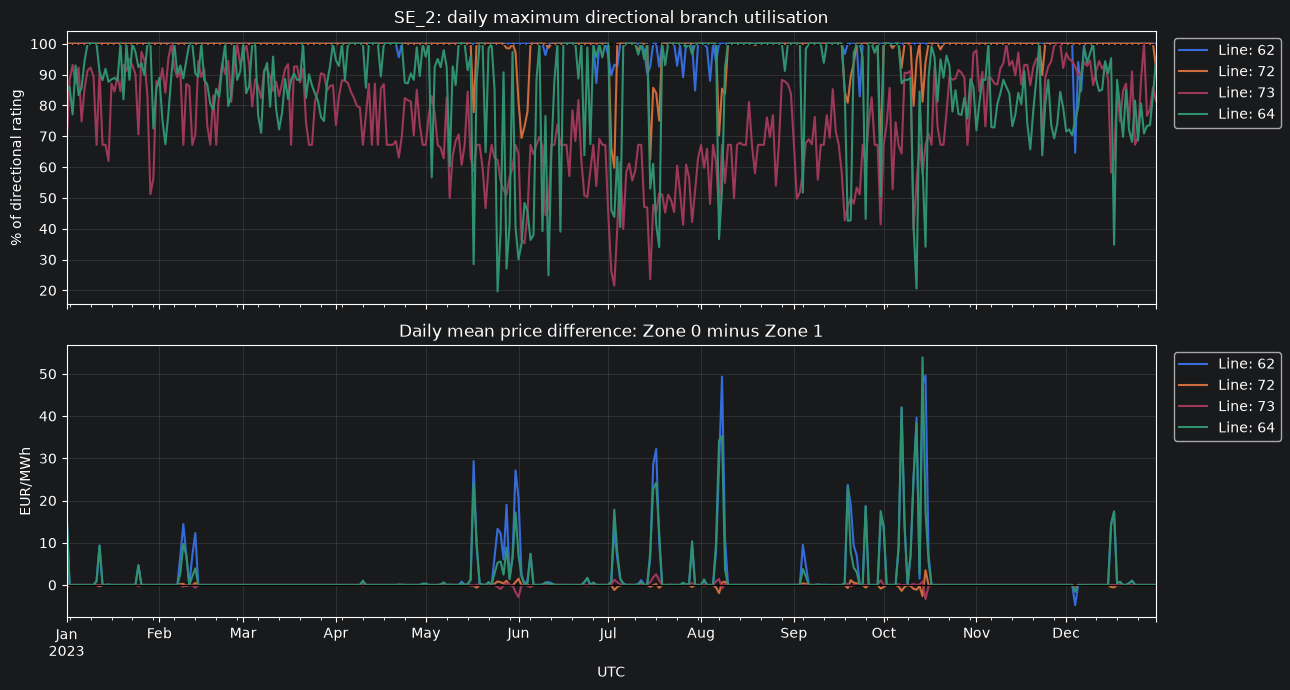

In [187]:
focus_branches = [
    key for key, zones in branch_details.items() if FOCUS_ZONE in zones
]
# Most heavily used connections first; at most six curves keep the plot readable.
focus_branches = sorted(
    focus_branches,
    key=lambda key: loading_by_branch[key].mean()
        if loading_by_branch[key].notna().any() else -np.inf,
    reverse=True,
)[:6]

if focus_branches:
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    (100 * loading_by_branch[focus_branches]).resample("D").max().plot(ax=axes[0])
    axes[0].axhline(100, color="black", linewidth=0.8, linestyle="--")
    axes[0].set(title=f"{FOCUS_ZONE}: daily maximum directional branch utilisation", ylabel="% of directional rating")
    axes[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    spread_plot = pd.DataFrame({
        key: prices[branch_details[key][0]] - prices[branch_details[key][1]]
        for key in focus_branches
    })
    spread_plot.resample("D").mean().plot(ax=axes[1])
    axes[1].axhline(0, color="black", linewidth=0.8)
    axes[1].set(title="Daily mean price difference: Zone 0 minus Zone 1", ylabel="EUR/MWh", xlabel="UTC")
    axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    plt.show()
else:
    print(f"No selected inter-zone branches incident to {FOCUS_ZONE}.")

## 13. Hydro: reservoir size, inflow, operation and water values

Reservoir hydro is a `StorageUnit`, not a fuel-burning generator. Its dispatch can have an opportunity cost even when its direct marginal cost is small.

Look for:
- unusually large energy capacity relative to turbine power (`max_hours`);
- long stretches near full or empty reservoirs;
- highly flexible seasonal dispatch under full-year perfect foresight;
- spillage, inflow seasonality and whether hydro output follows residual demand.

**Units matter:** inflow and spillage refer to the storage energy balance. Electrical discharge is converted back to that basis using `efficiency_dispatch` before comparison. The annual table distinguishes TWh stored from TWh electrical output.

The initial state for cyclic reservoirs is optimised, not an observed 1 January reservoir level. This notebook does not introduce historical reservoir observations or terminal water values.

In [188]:
hydro_meta = smeta.loc[smeta.carrier.eq("hydro")].copy()
hydro_summary = pd.DataFrame()
hydro_zone_data = {}

if hydro_meta.empty:
    print("No reservoir-hydro StorageUnits in DIAG_ZONES.")
else:
    hid = hydro_meta.index
    hydro_meta["Energy capacity MWh"] = hydro_meta.p_nom * hydro_meta.max_hours
    hsoc = output_series("storage_units", "state_of_charge", hid)
    hdispatch = output_series("storage_units", "p_dispatch", hid)
    hinflow = dense_input("StorageUnit", "inflow", hid)
    hspill = output_series("storage_units", "spill", hid)
    # Missing spill outputs must not silently become zero.
    hefficiency = dense_input("StorageUnit", "efficiency_dispatch", hid).where(lambda x: x.gt(0))
    hwithdrawal = hdispatch.div(hefficiency)
    fraction = hsoc.div(hydro_meta["Energy capacity MWh"].where(
        hydro_meta["Energy capacity MWh"].gt(0)
    ), axis=1)
    valid_soc = fraction.notna()

    hydro_summary = hydro_meta[[
        "zone", "bus", "p_nom", "max_hours", "Energy capacity MWh",
        "cyclic_state_of_charge", "state_of_charge_initial",
    ]].copy()
    hydro_summary["Mean reservoir fill (%)"] = 100 * fraction.mean()
    hydro_summary["Near empty hours (%)"] = masked_percent(
        fraction.le(SOC_BOUND_RTOL), valid_soc
    )
    hydro_summary["Near full hours (%)"] = masked_percent(
        fraction.ge(1 - SOC_BOUND_RTOL), valid_soc
    )
    hydro_summary["Electrical output TWh"] = hdispatch.mul(weights, axis=0).sum(min_count=1) / 1e6
    hydro_summary["Inflow TWh stored"] = hinflow.mul(water_weights, axis=0).sum(min_count=1) / 1e6
    hydro_summary["Withdrawal TWh stored"] = hwithdrawal.mul(water_weights, axis=0).sum(min_count=1) / 1e6
    hydro_summary["Spillage TWh stored"] = hspill.mul(water_weights, axis=0).sum(min_count=1) / 1e6
    hydro_summary["Spill output coverage (%)"] = 100 * hspill.notna().mean()
    hydro_summary["State-of-charge coverage (%)"] = 100 * valid_soc.mean()
    display(hydro_summary.sort_values(["zone", "Energy capacity MWh"], ascending=[True, False]).round(3))

    for zone, group in hydro_meta.groupby("zone"):
        ids = group.index
        capacity = group["Energy capacity MWh"].sum(min_count=1)
        # Only sum complete unit sets to avoid changing the regional total silently.
        hydro_zone_data[zone] = pd.DataFrame({
            "Reservoir fill (%)": 100 * hsoc[ids].sum(axis=1, min_count=len(ids)) / capacity
                if capacity > 0 else np.nan,
            "Inflow (GW stored)": hinflow[ids].sum(axis=1, min_count=len(ids)) / 1e3,
            "Withdrawal (GW stored)": hwithdrawal[ids].sum(axis=1, min_count=len(ids)) / 1e3,
            "Spillage (GW stored)": hspill[ids].sum(axis=1, min_count=len(ids)) / 1e3,
        })

    annual_hydro = hydro_summary.groupby("zone")[[
        "p_nom", "Energy capacity MWh", "Electrical output TWh",
        "Inflow TWh stored", "Withdrawal TWh stored", "Spillage TWh stored",
    ]].sum(min_count=1)
    print("Regional sums below: inspect unit-level coverage above before interpreting totals.")
    display(annual_hydro.round(3))

,zone,bus,p_nom,max_hours,Energy capacity MWh,cyclic_state_of_charge,state_of_charge_initial,Mean reservoir fill (%),Near empty hours (%),Near full hours (%),Electrical output TWh,Inflow TWh stored,Withdrawal TWh stored,Spillage TWh stored,Spill output coverage (%),State-of-charge coverage (%)
name,,,,,,,,,,,,,,,,
DE00 hydro,DE_LU,DE00,398.210,753.371,3.000000e+05,True,0.0,53.227,7.934,3.801,1.621,1.801,1.801,0.0,100.0,100.0
FI00 hydro,FI,FI00,1568.000,3507.653,5.500000e+06,True,0.0,86.449,0.000,10.011,7.745,8.605,8.605,0.0,100.0,100.0
NOS1 hydro,NO_1,NOS1,2761.880,3400.938,9.392983e+06,True,0.0,72.538,0.000,3.847,10.200,11.333,11.333,0.0,100.0,100.0
NOS2 hydro,NO_2,NOS2,11184.080,1820.013,2.035518e+07,True,0.0,67.544,0.000,4.053,41.304,45.893,45.893,0.0,100.0,100.0
NOM1 hydro,NO_3,NOM1,4334.160,2625.423,1.137900e+07,True,0.0,75.358,0.000,6.164,16.006,17.785,17.785,0.0,100.0,100.0
NON1 hydro,NO_4,NON1,5162.980,3839.666,1.982412e+07,True,0.0,79.119,0.000,6.142,19.067,21.186,21.186,0.0,100.0,100.0
NOS5 hydro,NO_5,NOS5,7591.630,3088.759,2.344872e+07,True,0.0,71.009,0.000,3.687,28.036,31.152,31.152,0.0,100.0,100.0
SE01 hydro,SE_1,SE01,5035.040,2746.993,1.383122e+07,True,0.0,75.279,0.000,7.066,20.459,22.733,22.733,0.0,100.0,100.0
SE02 hydro,SE_2,SE02,5854.785,2746.993,1.608305e+07,True,0.0,75.435,0.000,6.130,23.790,26.434,26.434,0.0,100.0,100.0


Regional sums below: inspect unit-level coverage above before interpreting totals.


,p_nom,Energy capacity MWh,Electrical output TWh,Inflow TWh stored,Withdrawal TWh stored,Spillage TWh stored
zone,,,,,,
DE_LU,398.210,3.000000e+05,1.621,1.801,1.801,0.0
FI,1568.000,5.500000e+06,7.745,8.605,8.605,0.0
NO_1,2761.880,9.392983e+06,10.200,11.333,11.333,0.0
NO_2,11184.080,2.035518e+07,41.304,45.893,45.893,0.0
NO_3,4334.160,1.137900e+07,16.006,17.785,17.785,0.0
NO_4,5162.980,1.982412e+07,19.067,21.186,21.186,0.0
NO_5,7591.630,2.344872e+07,28.036,31.152,31.152,0.0
SE_1,5035.040,1.383122e+07,20.459,22.733,22.733,0.0
SE_2,5854.785,1.608305e+07,23.790,26.434,26.434,0.0


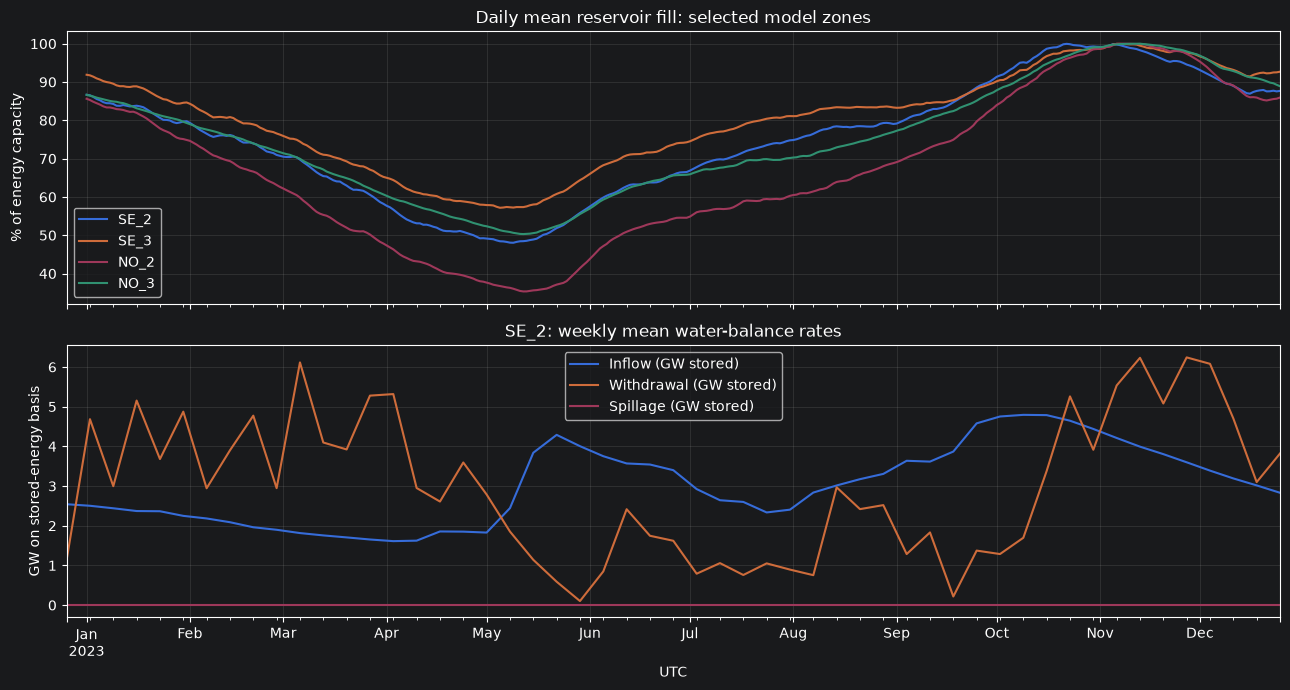

Hydro water-value duals were not exported in this network.
No zero water value is inferred, and no re-solve is performed.


In [189]:
if hydro_zone_data:
    hydro_zones = [
        zone for zone in [FOCUS_ZONE, "SE_2", "SE_3", "NO_2", "NO_3"]
        if zone in hydro_zone_data
    ]
    hydro_zones = list(dict.fromkeys(hydro_zones)) or list(hydro_zone_data)[:4]
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    for zone in hydro_zones:
        hydro_zone_data[zone]["Reservoir fill (%)"].resample("D").mean().plot(
            ax=axes[0], label=zone
        )
    axes[0].set(title="Daily mean reservoir fill: selected model zones", ylabel="% of energy capacity")
    axes[0].legend()

    hydro_focus = FOCUS_ZONE if FOCUS_ZONE in hydro_zone_data else hydro_zones[0]
    hydro_zone_data[hydro_focus][[
        "Inflow (GW stored)", "Withdrawal (GW stored)", "Spillage (GW stored)"
    ]].resample("W").mean().plot(ax=axes[1])
    axes[1].set(title=f"{hydro_focus}: weekly mean water-balance rates",
                ylabel="GW on stored-energy basis", xlabel="UTC")
    fig.tight_layout()
    plt.show()

    stored_duals = n.storage_units_t.get("mu_energy_balance", pd.DataFrame())
    dual_ids = hydro_meta.index.intersection(stored_duals.columns)
    if len(dual_ids) and stored_duals[dual_ids].notna().any().any():
        water_values = stored_duals.reindex(columns=dual_ids).copy()
        water_values.index = prices.index
        ax = water_values.resample("W").mean().plot()
        ax.set(title="Exported reservoir energy-balance duals: weekly means",
               ylabel="EUR/MWh stored (one-hour weights)", xlabel="UTC")
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
        plt.tight_layout()
        plt.show()
    else:
        print("Hydro water-value duals were not exported in this network.")
        print("No zero water value is inferred, and no re-solve is performed.")
else:
    print("Hydro plots skipped: no reservoir-hydro units in the diagnostic zones.")

## 14. Nuclear and biomass: fixed availability, flat costs and CHP

A constant nuclear `p_max_pu` is a **constant hourly output ceiling**. It is not a dated outage schedule and need not equal the realised annual capacity factor. A country-wide ceiling can reproduce an annual derating while missing the timing of maintenance.

For biomass, inspect the actual cost range, hourly output bounds and frequency of full output. A constant fuel assumption and an electricity-only dispatch model can produce a different operating pattern from heat-driven CHP. The notebook describes the saved inputs; it does not force extra cost variation.

The original 2023 result misplaced Ringhals/Oskarshamn in SE4. The inventory flags this if it is still present. A newer copy of the source code does not repair the existing NetCDF.

If the optional local `data/hindcast/powerplants_YEAR.csv` exists, individual plants and CHP labels are displayed too. No file is downloaded automatically.

,zone,bus,carrier,p_nom,efficiency,Availability min,Availability max,Availability std,Marginal cost min,Marginal cost mean,...,Interior dispatch (%),Interior & price-match (%),Valid output hours,Committable,Minimum dispatch p.u. (min),Minimum dispatch p.u. (max),Constant availability ceiling,Constant stored marginal cost,Static ramp limit up p.u.,Static ramp limit down p.u.
name,,,,,,,,,,,,,,,,,,,,,
DE00 biomass,DE_LU,DE00,biomass,7985.5792,0.4648,1.000,1.000,0.0,20.1187,20.1187,...,0.2169,0.2169,8760,False,0.0,0.0,True,True,NaN,NaN
LUG1 biomass,DE_LU,LUG1,biomass,2.8000,0.4680,1.000,1.000,0.0,19.9799,19.9799,...,0.0000,0.0000,8760,False,0.0,0.0,True,True,NaN,NaN
DKW1 biomass,DK_1,DKW1,biomass,661.0000,0.4680,1.000,1.000,0.0,19.9799,19.9799,...,0.0000,0.0000,8760,False,0.0,0.0,True,True,NaN,NaN
DKE1 biomass,DK_2,DKE1,biomass,1120.0000,0.4680,1.000,1.000,0.0,19.9799,19.9799,...,0.0913,0.0913,8760,False,0.0,0.0,True,True,NaN,NaN
FI00 biomass,FI,FI00,biomass,4153.7400,0.4680,1.000,1.000,0.0,19.9799,19.9799,...,0.0114,0.0114,8760,False,0.0,0.0,True,True,NaN,NaN
SE01 biomass,SE_1,SE01,biomass,88.0000,0.4680,1.000,1.000,0.0,19.9799,19.9799,...,0.0000,0.0000,8760,False,0.0,0.0,True,True,NaN,NaN
SE02 biomass,SE_2,SE02,biomass,538.8000,0.4680,1.000,1.000,0.0,19.9799,19.9799,...,0.0114,0.0114,8760,False,0.0,0.0,True,True,NaN,NaN
SE03 biomass,SE_3,SE03,biomass,2117.7000,0.4680,1.000,1.000,0.0,19.9799,19.9799,...,0.0000,0.0000,8760,False,0.0,0.0,True,True,NaN,NaN
SE04 biomass,SE_4,SE04,biomass,441.1000,0.4680,1.000,1.000,0.0,19.9799,19.9799,...,0.0000,0.0000,8760,False,0.0,0.0,True,True,NaN,NaN


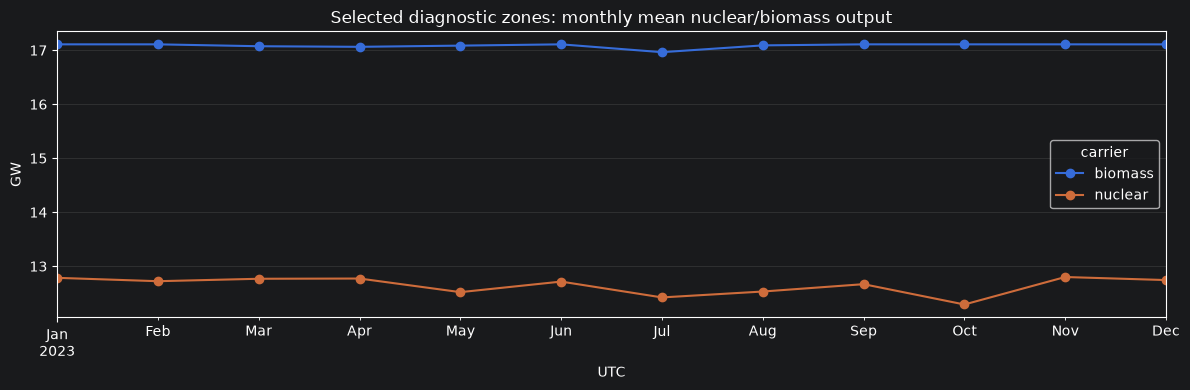

,bus,p_nom,p_max_pu,bidding_zone
name,,,,
SE03 nuclear,SE03,7184.0,0.779,SE_3


No Swedish nuclear capacity is mapped outside SE3 in this saved result.


,Name,Capacity,bus,bidding_zone,lat,lon
142422,Forsmark 3,1208.0,SE03,SE_3,60.4028,18.17440
142423,Forsmark 2,1160.0,SE03,SE_3,60.4028,18.17440
142424,Forsmark 1,1078.0,SE03,SE_3,60.4028,18.17440
142437,Ringhals 4,1171.0,SE03,SE_3,57.2574,12.10870
142438,Ringhals 3,1117.0,SE03,SE_3,57.2574,12.10870
142439,Oskarshamn 3,1450.0,SE03,SE_3,57.4166,16.67301


Source biomass capacity (MW)
bidding_zone Set                                
DE_LU        CHP                         7467.20
             PP                           446.68
             NaN                           74.50
DK_1         CHP                          132.00
             PP                            35.00
             NaN                          494.00
DK_2         PP                          1053.00
             NaN                           67.00
FI           PP                          3229.74
             Store                         46.00
             NaN                          878.00
SE_1         NaN                           88.00
SE_2         NaN                          538.80
SE_3         CHP                          305.00
             PP                           741.30
             Store                         38.00
             NaN                         1033.40
SE_4         NaN                          441.10

A CHP label in the source is not evidence that heat constraints are in the solved model.


In [190]:
thermal_ids = gmeta.index[gmeta.carrier.isin(["nuclear", "biomass"])]
if len(thermal_ids):
    thermal_table = generator_diagnostics.loc[thermal_ids].copy()
    thermal_table["Minimum dispatch p.u. (min)"] = gmin[thermal_ids].min()
    thermal_table["Minimum dispatch p.u. (max)"] = gmin[thermal_ids].max()
    thermal_table["Constant availability ceiling"] = (
        gmax[thermal_ids].max().sub(gmax[thermal_ids].min()).abs().le(1e-10)
        & gmax[thermal_ids].notna().any()
    )
    thermal_table["Constant stored marginal cost"] = (
        gcost[thermal_ids].max().sub(gcost[thermal_ids].min()).abs().le(1e-8)
        & gcost[thermal_ids].notna().any()
    )
    thermal_table["Static ramp limit up p.u."] = gmeta.loc[thermal_ids, "ramp_limit_up"]
    thermal_table["Static ramp limit down p.u."] = gmeta.loc[thermal_ids, "ramp_limit_down"]
    display(thermal_table.sort_values(["carrier", "zone"]).round(4))

    monthly_thermal = gp[thermal_ids].T.groupby(gmeta.loc[thermal_ids, "carrier"]).sum(min_count=1).T
    monthly_thermal = monthly_thermal.resample("MS").mean().div(1e3)
    ax = monthly_thermal.plot(marker="o")
    ax.set(title="Selected diagnostic zones: monthly mean nuclear/biomass output",
           ylabel="GW", xlabel="UTC")
    plt.tight_layout()
    plt.show()

swedish_nuclear = n.generators.loc[
    n.generators.carrier.eq("nuclear")
    & n.generators.bus.map(n.buses.country).eq("SE"),
    ["bus", "p_nom", "p_max_pu"],
].copy()
swedish_nuclear["bidding_zone"] = swedish_nuclear.bus.map(zone_of_bus)
display(swedish_nuclear)
outside_se3 = swedish_nuclear.loc[swedish_nuclear.bidding_zone.ne("SE_3"), "p_nom"].sum()
if outside_se3 > 0:
    print(f"Spatial issue in this saved result: {outside_se3:,.0f} MW of Swedish nuclear is outside SE3.")
    print("Keep this baseline labelled as originally built; this cell does not move any assets.")
else:
    print("No Swedish nuclear capacity is mapped outside SE3 in this saved result.")

PLANTS = PROJECT_ROOT / f"data/hindcast/powerplants_{YEAR}.csv"
if PLANTS.is_file():
    source_plants = pd.read_csv(PLANTS)
    required = {"Name", "Country", "Fueltype", "Capacity", "bus"}
    if not required.issubset(source_plants.columns):
        print("Individual-plant table skipped: missing columns", sorted(required - set(source_plants)))
    else:
        source_plants["bidding_zone"] = source_plants.bus.map(zone_of_bus)
        display(source_plants.loc[
            source_plants.Country.eq("SE") & source_plants.Fueltype.eq("Nuclear")
        ].reindex(columns=["Name", "Capacity", "bus", "bidding_zone", "lat", "lon"]))
        if "Set" in source_plants:
            bio = source_plants.loc[
                source_plants.Fueltype.isin(["Bioenergy", "Solid Biomass", "Biogas", "biomass"])
                & source_plants.bidding_zone.isin(diag_zones)
            ]
            display(bio.groupby(["bidding_zone", "Set"], dropna=False).Capacity
                    .sum(min_count=1).round(2).to_frame("Source biomass capacity (MW)"))
            print("A CHP label in the source is not evidence that heat constraints are in the solved model.")
else:
    print(f"Optional individual-plant CSV not found: {PLANTS.name}")

## 15. Renewable availability, residual demand and a diagnostic checklist

Residual demand here is **local model demand minus available wind, solar and run-of-river output**. It can be negative, and it excludes imports, reservoir hydro and thermal generation. It is not the full power balance.

The scatter plot asks whether price responds to that local residual demand. A weak relationship may reflect trade or storage decisions; it does not by itself identify an error. A flat price alongside changing residual demand directs attention to common costs, water values, available imports and operating constraints.

The renewable table compares availability with dispatch. Wind/solar availability comes from the model input profiles; it has not been compared with historical generation here.

,Zone,Carrier,Nominal MW,Availability capacity factor,Dispatch capacity factor,Un-dispatched availability (%),Valid hours
0,DE_LU,offwind-ac,8473.000,0.500,0.500,0.000,8760
1,DE_LU,onwind,61220.340,0.262,0.262,0.000,8760
2,DE_LU,ror,4014.000,0.507,0.507,0.000,8760
3,DE_LU,solar,75276.260,0.122,0.122,0.000,8760
4,DK_1,offwind-ac,1492.664,0.527,0.527,0.004,8760
5,DK_1,onwind,3808.419,0.412,0.412,0.000,8760
6,DK_1,solar,2690.639,0.123,0.123,0.000,8760
7,DK_2,offwind-ac,976.436,0.530,0.530,0.000,8760
8,DK_2,onwind,999.491,0.468,0.468,0.000,8760
9,DK_2,solar,838.361,0.129,0.129,0.000,8760


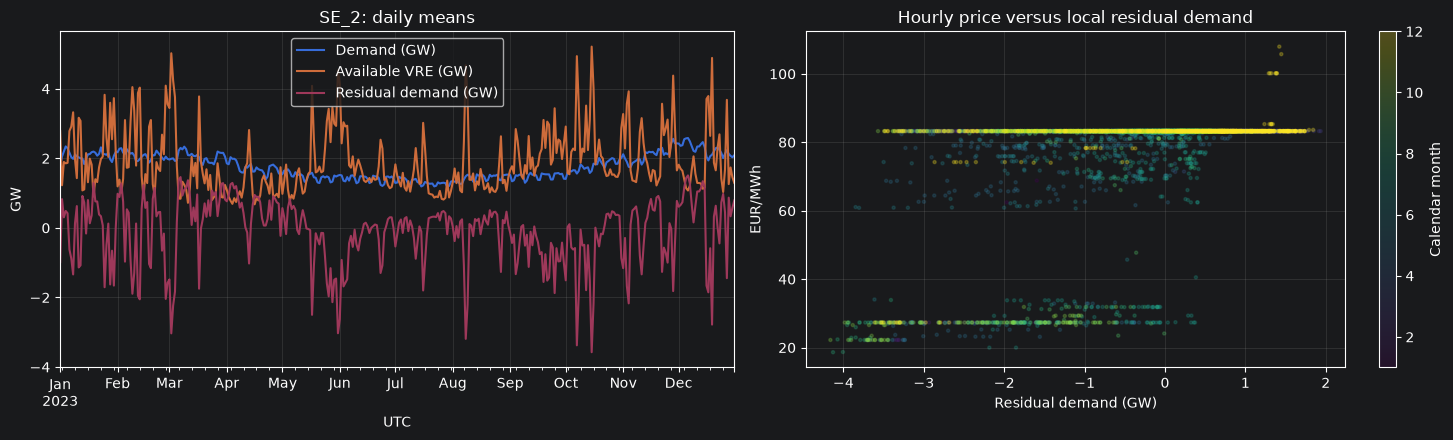

In [191]:
vre_carriers = ["onwind", "offwind-ac", "offwind-dc", "solar", "ror"]
vre_rows = []
for (zone, carrier), group in gmeta.loc[
    gmeta.carrier.isin(vre_carriers) & gmeta["sign"].eq(1)
].groupby(["zone", "carrier"]):
    ids = group.index
    available = gupper[ids].sum(axis=1, min_count=len(ids))
    actual = gp[ids].sum(axis=1, min_count=len(ids))
    valid = available.notna() & actual.notna()
    possible_energy = available[valid].mul(weights[valid]).sum()
    actual_energy = actual[valid].mul(weights[valid]).sum()
    nominal_energy = group.p_nom.sum() * weights[valid].sum()
    vre_rows.append({
        "Zone": zone, "Carrier": carrier,
        "Nominal MW": group.p_nom.sum(),
        "Availability capacity factor": possible_energy / nominal_energy if nominal_energy > 0 else np.nan,
        "Dispatch capacity factor": actual_energy / nominal_energy if nominal_energy > 0 else np.nan,
        "Un-dispatched availability (%)": 100 * (available[valid] - actual[valid]).clip(lower=0)
            .mul(weights[valid]).sum() / possible_energy if possible_energy > 0 else np.nan,
        "Valid hours": int(valid.sum()),
    })
renewable_diagnostics = pd.DataFrame(vre_rows)
display(renewable_diagnostics.round(3))

focus_vre = gmeta.index[
    gmeta.zone.eq(FOCUS_ZONE) & gmeta.carrier.isin(vre_carriers) & gmeta["sign"].eq(1)
]
if len(focus_vre):
    available_vre = gupper[focus_vre].sum(axis=1, min_count=len(focus_vre))
    residual = pd.DataFrame({
        "Demand (GW)": demand[FOCUS_ZONE] / 1e3,
        "Available VRE (GW)": available_vre / 1e3,
        "Residual demand (GW)": (demand[FOCUS_ZONE] - available_vre) / 1e3,
        "Price (EUR/MWh)": prices[FOCUS_ZONE],
    })
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    residual[["Demand (GW)", "Available VRE (GW)", "Residual demand (GW)"]].resample("D").mean().plot(ax=axes[0])
    axes[0].set(title=f"{FOCUS_ZONE}: daily means", ylabel="GW", xlabel="UTC")
    pair = residual[["Residual demand (GW)", "Price (EUR/MWh)"]].dropna()
    points = axes[1].scatter(
        pair.iloc[:, 0], pair.iloc[:, 1], c=pair.index.month,
        s=5, alpha=0.25, cmap="viridis", rasterized=True,
    )
    axes[1].set(title="Hourly price versus local residual demand",
                xlabel="Residual demand (GW)", ylabel="EUR/MWh")
    fig.colorbar(points, ax=axes[1], label="Calendar month")
    fig.tight_layout()
    plt.show()
else:
    print(f"No wind/solar/run-of-river generators in {FOCUS_ZONE}. Residual-demand plot skipped.")

## Read the findings before changing the model

Use the tables to answer these questions in order:

| Question | Where to look | What the result can establish |
| --- | --- | --- |
| Are assets and demand placed in the intended zones? | Sections 9 and 14, individual plant CSV | An allocation problem; inspect the geographic build before tuning costs |
| Are Nordic prices nearly identical, and does this differ historically? | Section 10 | Quantifies model variation and regional separation, with paired reference coverage |
| Do biomass costs coincide with prices while output is interior? | Section 11 | Price-setting candidates, not a proof of the marginal technology |
| Are connecting branches near their directional limits when prices separate? | Section 12 | Identifies model bottleneck candidates; historical market-capacity validation is separate |
| Are reservoirs very large, rarely constrained or seasonally too flexible? | Section 13 | Describes model hydro operation; observed reservoir levels/inflows are still needed for validation |
| Are nuclear availability and biomass costs constant? | Section 14 | Reveals the saved assumptions, not their historical accuracy |
| Do renewable availability and local residual demand vary while price stays flat? | Section 15 | Helps distinguish local supply variation from price response |

Keep this result as the **original baseline**. Geographic corrections, dated
outage inputs, revised hydro terminal conditions, limited foresight and
additional CHP constraints should be documented as separate changes or
sensitivity cases. Increasing price variation is not itself evidence of a
better model: compare hourly errors, bias, coverage, dispatch and load shedding.

The notebook reads only local files, performs no downloads and never calls an
optimiser. It does not overwrite the network, apply geographic fixes, set water
values, perturb fuel costs or submit HPC jobs. The extended cells have not been
executed against your solved network.